<a href="https://colab.research.google.com/github/kmrios/IS-4487-F26/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
filepath = 'cleaned_airbnb_data_6.csv'
df = pd.read_csv(filepath)

# Preview the first few rows of the data
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,price_cleaned
0,3781,https://www.airbnb.com/rooms/3781,20260919134146,2026-09-20,NaN,Harborside-Walk to subway,Fully separate apartment in a two apartment bu...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,4804,...,4.85,4.89,NaN,NaN,1,1,0,0,0.20,111.62
1,5506,https://www.airbnb.com/rooms/5506,20260919134146,2026-09-20,NaN,** Fort Hill Inn Private! Minutes to center!**,**THE BEST Value in BOSTON!!*** PRIVATE GUEST ...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,8229,...,4.59,4.78,STR-490093,NaN,11,11,0,0,0.68,189.00
2,6695,https://www.airbnb.com/rooms/6695,20260919134146,2026-09-20,NaN,"Fort Hill Inn *Sunny* 1 bedroom, condo duplex","Comfortable, Fully Equipped private apartment...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,8229,...,4.55,4.73,STR-491702,NaN,11,11,0,0,0.69,254.38
3,10811,https://www.airbnb.com/rooms/10811,20260919134146,2026-09-20,previous scrape,Bostons Best Rentals -Studio Prestigious Back Bay,Bostons Best Rentals offers a Stunning Back Ba...,NaN,https://a0.muscache.com/pictures/45735/27548f7...,38997,...,5.00,4.67,NaN,NaN,10,10,0,0,0.07,134.62
4,10813,https://www.airbnb.com/rooms/10813,20260919134146,2026-09-20,NaN,The Back Bay Nook -Brownstone in Prestigious ...,Stunning Back Bay furnished studio apartment. ...,NaN,https://a0.muscache.com/pictures/20b5b9c9-e1f4...,38997,...,5.00,4.86,NaN,NaN,10,10,0,0,0.08,169.75


## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

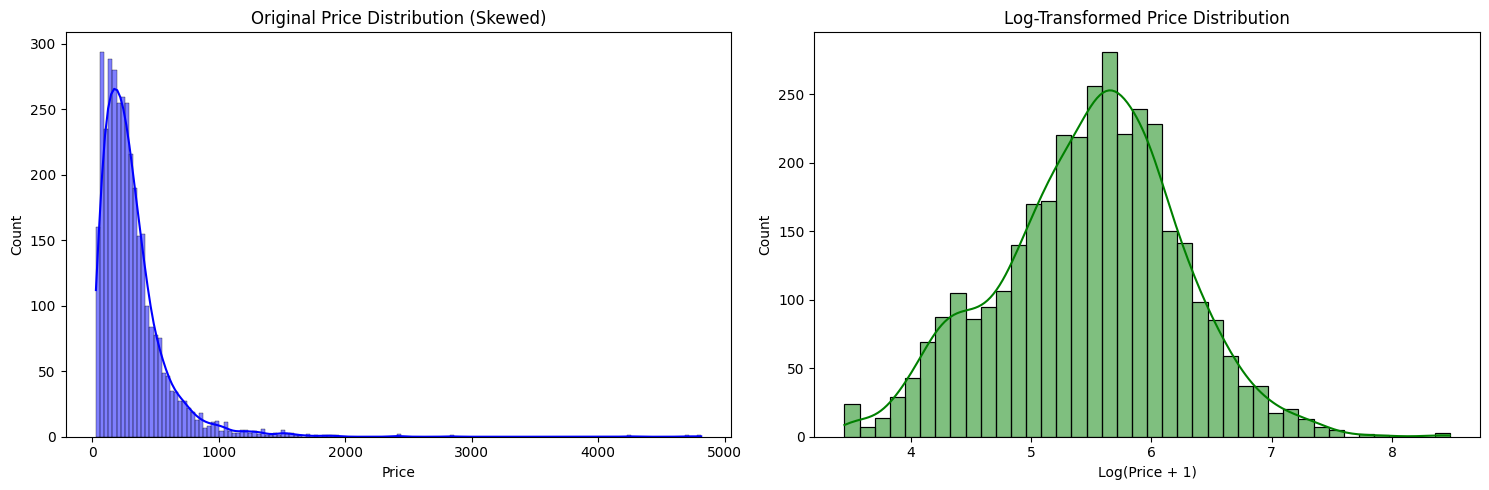

Original skewness: 4.93
Log-transformed skewness: -0.11


In [2]:
# 2. Check for Skew in a Numeric Column
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# We will examine the 'price_cleaned' column
original_data = df['price_cleaned'].dropna()

# Apply Log Transformation (adding 1 in case there are 0 or negative values)
transformed_data = np.log1p(original_data)

# Plotting the comparisons
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Original Histogram
sns.histplot(original_data, kde=True, ax=axes[0], color='blue')
axes[0].set_title('Original Price Distribution (Skewed)')
axes[0].set_xlabel('Price')
axes[0].set_ylabel('Count')

# Transformed Histogram
sns.histplot(transformed_data, kde=True, ax=axes[1], color='green')
axes[1].set_title('Log-Transformed Price Distribution')
axes[1].set_xlabel('Log(Price + 1)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

# Calculate Skewness scores to show analytical proof
print(f"Original skewness: {original_data.skew():.2f}")
print(f"Log-transformed skewness: {transformed_data.skew():.2f}")

### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. Original Price Distribution.

2. I tried log tranformation to get rid of some of the skewness because otherwise it was pressed to the edges of the left side with some fairly large outliers to the right.

3. By transforming the data it became much more normalized, which will allow it to be easily used for computation in later steps, but also allows for easier visual analysis as wse can actually see the counts on the left side instead of glancing at a tiny blur of lines.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [3]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Min-Max scale


# Z-score scale



In [4]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 1. Identify two numeric columns with different ranges
# 'accommodates' (ranges from 1 to ~16)
# 'availability_365' (ranges from 0 to 365)

# Fill missing values with median to ensure scaling works smoothly
df['accommodates'] = df['accommodates'].fillna(df['accommodates'].median())
df['availability_365'] = df['availability_365'].fillna(df['availability_365'].median())

# Show original ranges
print("Original Ranges:")
print(f"Accommodates: Min = {df['accommodates'].min()}, Max = {df['accommodates'].max()}")
print(f"Availability 365: Min = {df['availability_365'].min()}, Max = {df['availability_365'].max()}")

# 2. Min-Max Scaling on 'accommodates' (scale to 0-1 range)
min_max_scaler = MinMaxScaler()
df['accommodates_minmax'] = min_max_scaler.fit_transform(df[['accommodates']])

# 3. Z-score Normalization (Standardization) on 'availability_365'
std_scaler = StandardScaler()
df['availability_365_zscore'] = std_scaler.fit_transform(df[['availability_365']])

# Verify changes
print("\nScaled Ranges & Metrics:")
print(f"Accommodates (Min-Max): Min = {df['accommodates_minmax'].min():.2f}, Max = {df['accommodates_minmax'].max():.2f}")
print(f"Availability 365 (Z-Score): Mean = {df['availability_365_zscore'].mean():.2f}, Std = {df['availability_365_zscore'].std():.2f}")

# Preview new columns
df[['accommodates', 'accommodates_minmax', 'availability_365', 'availability_365_zscore']].head()

Original Ranges:
Accommodates: Min = 1, Max = 16
Availability 365: Min = 0, Max = 365

Scaled Ranges & Metrics:
Accommodates (Min-Max): Min = 0.00, Max = 1.00
Availability 365 (Z-Score): Mean = 0.00, Std = 1.00


,accommodates,accommodates_minmax,availability_365,availability_365_zscore
0,2,0.066667,231,0.155123
1,2,0.066667,108,-0.845105
2,4,0.200000,121,-0.739390
3,3,0.133333,323,0.903261
4,2,0.066667,338,1.025241



### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1. I did accomodates and availability_365 using min max and z score respectively.

2. Using the z score method with availability_365 cuts down the variables we are working with from over 300 to 0-1 (including decimals of course) making it easier to computate with a smaller range available. Additionally since accomodates typically has a range of 1-16, using the min max method makes the range more reasonable, because otherwise any that were at the 16 high point would have significantly more weight than those at 1.

3. Analysts at Airbnb who are trying to predict pricing patterns of recommend similarly based listing would benefit from this change.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [5]:
# 4. Group a Numeric Column into Categories
import pandas as pd

# Fill missing values in reviews with 0
df['number_of_reviews'] = df['number_of_reviews'].fillna(0)

# We will group 'number_of_reviews' into 3 bins: 'Low', 'Medium', and 'High'
# Since there are many listings with 0 reviews, we use duplicates='drop'
df['review_activity_category'] = pd.qcut(
    df['number_of_reviews'],
    q=3,
    labels=['Low', 'Medium', 'High'],
    duplicates='drop'
)

# Check the distribution of our new categorical column
print("Value counts for each category:")
print(df['review_activity_category'].value_counts())

# Let's inspect a preview of the mapping
df[['number_of_reviews', 'review_activity_category']].head(10)

Value counts for each category:
review_activity_category
Low       1500
High      1454
Medium    1414
Name: count, dtype: int64


,number_of_reviews,review_activity_category
0,27,Medium
1,144,High
2,144,High
3,9,Medium
4,7,Medium
5,2,Low
6,51,High
7,109,High
8,146,High
9,344,High


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. I chose to use reviews with 3 categories, low, medium, and high.

2. This would make it easier to summarize large amounts of data because it could easily be seen within each category instead of scoring through mountains of raw data.

3. This would help the promoters at airbnb because they would be able to reach out to those in the low category with suggestions to improve their ratings to make the site better overall and they could reach out to the highly ranked ones for promotional opportunities since they have a proven track record of good work.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [6]:
# 5. Create Two New Business-Relevant Variables

# Handle division by zero or NaN values in accommodates and price
df['price_cleaned'] = df['price_cleaned'].fillna(df['price_cleaned'].median())
df['accommodates'] = df['accommodates'].replace(0, 1)  # avoid division by zero

# 1. Ratio/Interaction feature: Price per person accommodated
df['price_per_accommodate'] = df['price_cleaned'] / df['accommodates']

# 2. Boolean flag: Is it a long-term stay listing (minimum nights > 30 days)?
df['minimum_nights'] = df['minimum_nights'].fillna(1)
df['is_long_term_stay'] = (df['minimum_nights'] > 30).astype(int)

# Preview the newly created columns
print("First 10 rows of newly created features:")
df[['price_cleaned', 'accommodates', 'price_per_accommodate', 'minimum_nights', 'is_long_term_stay']].head(10)

First 10 rows of newly created features:


,price_cleaned,accommodates,price_per_accommodate,minimum_nights,is_long_term_stay
0,111.62,2,55.810000,29.0,0
1,189.00,2,94.500000,1.0,0
2,254.38,4,63.595000,2.0,0
3,134.62,3,44.873333,91.0,1
4,169.75,2,84.875000,32.0,1
5,148.20,2,74.100000,60.0,1
6,188.90,6,31.483333,29.0,0
7,154.40,2,77.200000,5.0,0
8,101.55,3,33.850000,29.0,0
9,138.00,2,69.000000,1.0,0


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. price_per_accomodate to see the price per person able to stay at the property and is_long_term_stay to flag stays over 30 days.

2. The customers could use the price per to compare different properties and understand the actual cost of the room depending on how many people are staying there rather than the overarching cost not broken down by party. The long term stay flag would help hosts to know how long their property would be occupied on average which would be helpful if their proporety was not a full time airbnb, for example if it was a resort home in a ski town that the owners occassionally use for themselves.

3. Customers would have a better understanding of price and thus would be more likely to purchase, and airbnb hosts would have a better idea of the length of stay on average.



## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [7]:
# 6. Encode a Categorical Column
import pandas as pd

# We will choose 'room_type' as our categorical column
print("Unique values in 'room_type' before encoding:")
print(df['room_type'].value_counts(dropna=False))

# Use pd.get_dummies for One-Hot Encoding since room types are nominal (unordered)
# We'll keep prefix='room' so we can clearly identify these columns
room_type_encoded = pd.get_dummies(df['room_type'], prefix='room', dtype=int)

# Concatenate the new one-hot encoded columns back to the original DataFrame
df = pd.concat([df, room_type_encoded], axis=1)

# Display the new columns added to the DataFrame
print("\nNewly added encoded columns:")
print(room_type_encoded.columns.tolist())

# Preview the resulting columns
df[['room_type'] + room_type_encoded.columns.tolist()].head()

Unique values in 'room_type' before encoding:
room_type
Entire home/apt    3000
Private room       1278
Hotel room           85
Shared room           5
Name: count, dtype: int64

Newly added encoded columns:
['room_Entire home/apt', 'room_Hotel room', 'room_Private room', 'room_Shared room']


,room_type,room_Entire home/apt,room_Hotel room,room_Private room,room_Shared room
0,Entire home/apt,1,0,0,0
1,Entire home/apt,1,0,0,0
2,Entire home/apt,1,0,0,0
3,Entire home/apt,1,0,0,0
4,Entire home/apt,1,0,0,0


### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1. I used room type because the categories could not be easily analyzed without encoding them into numbers.
2. Since the variables were not ordinal (ie had no correct order) I used One-Hot encoding.
3. This could be used to see how many rooms of each category are posted in a certain location helping Airbnb promoters understand what types of properties are available in any given area. For example if the city offers primarily airbnb apartments, promoting a full house for a retreat would not be particularly helpful since there would only be a few available at any given time.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

Dataset exported successfully as 'cleaned_airbnb_data_7.csv'!
Final dimensions of the dataset: 4368 rows and 97 columns.


## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. Creating the bins felt more interactive because we often see data placed into categories for easy interpretation so it was the easiest for me to see the real life application instead of having to dig for deeper analysis.

2. The one-hot encoding of the room type would be most helpful. As explained in that reflection it would be helpful for an analyst or promoter to understand what properties were actually available in any given city.

3. I would simplify it. Right now there are too many categories and columns to pull from that creating a dashboard would be overwhelmingly complex and likely difficult to use.

4. As an entrepreneur my job is to have a general understanding of all business processes. From a data analytics standpoint, I would be likely to hire out a lot of the heavy code based analysis instead of spending a lot of time on it since it isn't my specialty. However excersizes like this are helpful to me because it gives me a sense of how complex an action is. For example putting things into little categories or bins. I now know around how long that takes, so if I'm quoted that a similar job would take days or weeks I can easily fact check the contractor and adjust my payment plan or find a new resource to use that is more transparent.



## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [9]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"

[NbConvertApp] Converting notebook assignment_07_data_transformation.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 426766 bytes to assignment_07_data_transformation.html
